In [1]:
import numpy as np
import scipy.stats as stats
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
PUBLIC_SRC = 'https://seshat.datasd.org/get_it_done_reports'
YEARS = [2021, 2022, 2023, 2024, 2025, 2026]
PRIVATE_CSV = 'data/gid_cases-001.csv'
ATTACH_CSV = 'data/public-attachments-cases.csv'
REFFERALS_CSV = 'data/referral data for UCSD-2026-11-02-23-09-16.csv'
WINDOW_START, WINDOW_END = '2023-01-01', '2026-10-01'

# Loading Datasets

## Loading public and private GID data

In [3]:
PUB_COLS = [
    'service_request_id', 'service_request_parent_id', 'date_requested', 'case_age_days', 'public_description',
    'case_record_type', 'service_name', 'service_name_detail', 'date_closed', 'status', 'case_origin', 'referred'
    ]

closed = pd.concat([pd.read_csv(f'{PUBLIC_SRC}/get_it_done_requests_closed_{y}_datasd.csv', usecols=PUB_COLS) for y in YEARS], ignore_index=True)
open_ = pd.read_csv(f'{PUBLIC_SRC}/get_it_done_requests_open_datasd.csv', usecols=PUB_COLS)

In [4]:
pub = pd.concat([closed, open_], ignore_index=True).drop_duplicates('service_request_id')

pub['date_requested'] = pd.to_datetime(pub['date_requested'])
pub['date_requested'] = pub['date_requested'].dt.tz_localize('UTC').dt.tz_convert('US/Pacific')
pub['date_closed'] = pd.to_datetime(pub['date_closed'])

pub = pub[(pub['date_requested'] >= WINDOW_START) & (pub['date_requested'] < WINDOW_END)].copy()

In [5]:
PRIV_COLS = [
    'Case Reason', 'Last Modified Date', 'Parent Case ID', 'Parent Case ID', 'Case Number',
    'Owner ID', 'Last Modified By ID', 'Created By ID', 'Created Date',
    ]

RENAME = {t:t.lower().replace(' ', '_') for t in PRIV_COLS}
RENAME.update({'Status': 'private_status'})
priv = pd.read_csv(PRIVATE_CSV, usecols=list(RENAME), dtype=str).rename(columns=RENAME)

In [6]:
priv['case_number'] = pd.to_numeric(priv['case_number'], errors='coerce')
priv = priv.dropna(subset=['case_number'])
priv['case_number'] = priv['case_number'].astype(int)
priv.drop_duplicates('case_number', inplace=True)

priv['last_modified_date'] = pd.to_datetime(priv['last_modified_date'])
priv['owner_type'] = priv['owner_id'].str[:3].map({'005': 'worker', '00G': 'queue'}).fillna('other')
priv['modified_by_worker'] = priv['last_modified_by_id'].str[:3].eq('005')
priv['case_number'] = priv['case_number'].astype(float)
priv.drop(columns=['owner_id', 'last_modified_by_id'], inplace=True)

In [7]:
datasd = pub.merge(priv, left_on='service_request_id', right_on='case_number', how='left')

## Loading referrals data

In [8]:
REF_COLS = ['Internal Case Referral Flag', 'Internal Referral Count']

REF_RENAME = {t:t.lower().replace(' ', '_') for t in REF_COLS}
REF_RENAME.update({'Case Number': 'ref_case_number', 'Status': 'referral_status'})
referrals_info = pd.read_csv(REFFERALS_CSV, encoding='latin-1', usecols=list(REF_RENAME)).rename(columns=REF_RENAME)

In [9]:
df = datasd.merge(referrals_info, left_on='service_request_id', right_on='ref_case_number', how='left').drop(columns='ref_case_number')

In [10]:
df.head()

,service_request_id,service_request_parent_id,date_requested,case_age_days,case_record_type,service_name,service_name_detail,date_closed,status,case_origin,...,created_date,last_modified_date,parent_case_id,case_reason,private_status,owner_type,modified_by_worker,internal_case_referral_flag,internal_referral_count,referral_status
0,4470480,NaN,2023-10-20 01:24:00-07:00,0.0,ESD Complaint/Report,Illegal Dumping,Illegal Dumping,2023-10-20,Closed,Worker App,...,2023-10-20 08:24:41.000,2023-10-20 08:24:53,NaN,Problem resolved,Closed,queue,True,NaN,NaN,NaN
1,4470495,NaN,2023-10-20 01:28:00-07:00,0.0,ESD Complaint/Report,Illegal Dumping,Illegal Dumping,2023-10-20,Closed,Worker App,...,2023-10-20 08:28:31.000,2023-10-20 08:28:43,NaN,Problem resolved,Closed,queue,True,NaN,NaN,NaN
2,4470497,NaN,2023-10-20 01:28:00-07:00,3.0,Parking,Parking Violation,Red Zone,2023-10-23,Closed,Mobile,...,2023-10-20 08:28:43.000,2023-10-23 12:52:12,NaN,NaN,Closed,queue,True,0.0,0.0,Closed
3,4470499,4470478.0,2023-10-20 01:28:00-07:00,6.0,Storm Water Code Enforcement,Stormwater Code Enforcement,SWPP - Storm Water Polution Prevention,2023-10-26,Closed,Mobile,...,2023-10-20 08:28:52.000,2023-12-19 05:39:15,5008z000006VfAxAAK,Not a Storm Water Issue,Closed,worker,True,0.0,0.0,Closed
4,4470521,NaN,2023-10-20 01:33:00-07:00,0.0,TSW,Graffiti - Public,NaN,2023-10-20,Closed,Crew/Self Generated,...,2023-10-20 08:33:39.000,2025-03-18 12:57:47,NaN,Problem resolved,Closed,queue,True,NaN,NaN,NaN


In [11]:
df['last_modified_date'] = df['last_modified_date'].dt.tz_localize('US/Pacific', ambiguous=True)
df['date_closed'] = pd.to_datetime(df['date_closed']).dt.tz_localize('US/Pacific')

In [12]:
parents = df.loc[df['case_age_days'] < 0., 'service_request_parent_id'].values
df = df[~((df['service_request_parent_id'].isin(parents)) | (df['service_request_id'].isin(parents)))]

In [13]:
df.fillna({'internal_case_referral_flag':0, 'internal_referral_count':0}, inplace=True)
df.drop(columns=['referral_status'], inplace=True)
df = df[(df['case_age_days'] >= 0) & (df['status'].isin(['Closed', 'Referred']))]

In [14]:
df.loc[df['internal_referral_count'] > 0, 'internal_case_referral_flag'] = 1.0

In [15]:
df.loc[(df['internal_case_referral_flag'] == 1.) & (df['internal_referral_count'] == 0.), ['service_request_id', 'date_requested', 'case_age_days', 'case_record_type', 'service_name', 'date_closed', 'status', 'referred', 'case_reason', 'private_status', 'internal_referral_count', 'internal_case_referral_flag']]

,service_request_id,date_requested,case_age_days,case_record_type,service_name,date_closed,status,referred,case_reason,private_status,internal_referral_count,internal_case_referral_flag
650640,4780714,2024-06-03 15:19:00-07:00,1.0,TSW,Graffiti - Public,2024-06-04 00:00:00-07:00,Referred,This report has been referred to Caltrans San ...,Problem resolved,Closed - Referred,0.0,1.0


In [16]:
df.loc[df['service_request_id'] == 4780714, 'internal_case_referral_flag'] = 0.

In [17]:
# Inplace function(s) and code to clean up referred column. Based on the frequency of referrals made
def categorize_referrals(txt):
    txt = str(txt).lower()
    if 'sdge' in txt or 'sdg&e' in txt:
        return 'sdg&e'
    if 'cox.com' in txt:
        return 'cox communications'
    if 'charter.com' in txt or 'spectrum' in txt:
        return 'spectrum'
    if 'att' in txt or 'at&t' in txt:
        return 'at&t'
    if 'cleanharbors' in txt:
        return 'clean harbors sanitation'
    if 'wm.com' in txt or 'waste management' in txt:
        return 'waste management'
    if 'republicservices' in txt or 'republic-services' in txt:
        return 'republic services'
    if 'edcodisposal' in txt:
        return 'edco disposal'
    if 'sdmts' in txt:
        return 'mts'
    if 'nctd.org' in txt:
        return 'nctd'
    if 'bnsf' in txt:
        return 'bnsf railroad'
    if 'caltrans' in txt or 'dot.ca.gov' in txt:
        return 'caltrans'
    if 'portofsandiego' in txt or 'port of san diego' in txt:
        return 'port of sd'
    if 'san.org' in txt:
        return 'sd international airport'
    if 'sandi.net' in txt:
        return 'sd unified school district'
    if 'ucsd.edu' in txt:
        return 'ucsd'
    if 'sdsu.edu' in txt:
        return 'sdsu'
    if 'sdccd.edu' in txt:
        return 'sdccd'
    if 'chulavistaca.gov' in txt:
        return 'city of chula vista'
    if 'sdcounty.ca.gov' in txt:
        return 'san diego county'
    if 'parks.ca.gov' in txt or 'wildlife.ca.gov' in txt:
        return 'california state parks/wildlife'
    if 'usps' in txt:
        return 'usps'
    if 'livelmh' in txt:
        return 'liberty military housing'
    if 'improvedtsd' in txt or 'ballparkdistrict' in txt or 'downtownsandiego.org' in txt:
        return 'downtown clean & safe / ballpark'
    if 'sdhumane' in txt:
        return 'sd humane society'
    if 'vector' in txt:
        return 'county vector control'
    if 'rms' in txt or 'retailsolutions' in txt or 'retailms.net' in txt:
        return 'retail solutions (rms)'
    if 'smartcart' in txt:
        return 'smart cart'
    if 'clearchannel' in txt:
        return 'clear channel'
    if 'outfront.com' in txt:
        return 'outfront media'
    if 'engineering' in txt:
        return 'field engineering'
    if 'facilitiesmaint' in txt:
        return 'facilities maintenance'
    if 'treepermit' in txt:
        return 'tree permits'
    if 'publicliability' in txt or 'riskmanagement' in txt:
        return 'risk management / public liability'
    if 'specialevents' in txt:
        return 'special events'
    if 'realestate' in txt:
        return 'real estate assets'
    if 'sdpd' in txt or 'police' in txt:
        return 'sdpd'
    if 'sdfd' in txt or 'fire' in txt:
        return 'sdfd'
    if 'wcm_gid' in txt or 'water' in txt:
        return 'water / wastewater (pud)'
    if 'jkafulides' in txt or 'parking' in txt:
        return 'parking meter repair'
    if 'sdlg' in txt or 'lifeguard' in txt:
        return 'lifeguards'
    if 'fit_dsd' in txt or 'development services' in txt:
        return 'development services (dsd)'
    if 'sdbusiness' in txt:
        return 'sd business / economic dev'
    if 'street division' in txt:
        return 'street division'
    if 't-row code compliance' in txt:
        return 't-row code compliance'     
    if 'sanitization contractor' in txt or 'environmental services' in txt or 'esd' in txt:
        return 'environmental services (esd)'
    if 'parks intake' in txt:
        return 'parks & recreation'
    if 'testing only' in txt:
        return 'test/invalid'
    if 'null' in txt:
        return 'error'
    return txt

def clean_referrals(df):
    df['referred'] = df['referred'].apply(categorize_referrals)
    # If the referral is not a specific organization (is an email), extract the email:
    df.loc[df['referred'].str.contains('@'), 'referred'] = df.loc[df['referred'].str.contains('@'), 'referred'].str.extract(r'([a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,})')[0].str.lower()
    df.loc[df['referred'] == 'nan', 'referred'] = np.nan

In [18]:
clean_referrals(df)

# Comparing `case_age_days` and `case_reason` based on internal* referrals

<!-- timeline (date fields) -->

### Is there a difference between ages (days) of cases based on if they are flagged for internal routing? What are the time (days) delays caused by many internal handoffs?

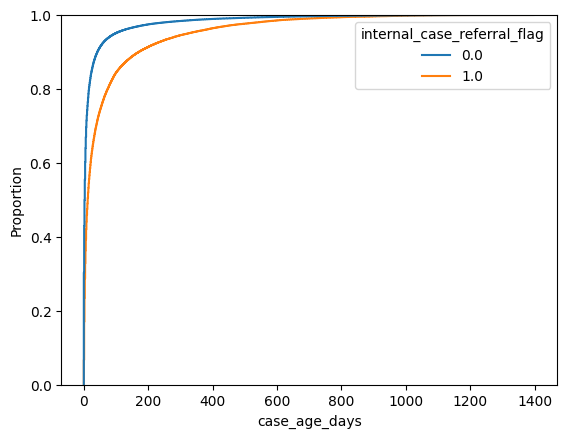

In [19]:
sns.ecdfplot(data=df, x='case_age_days', hue='internal_case_referral_flag')
plt.show()

In [20]:
internal_case_flag = df.loc[(df['internal_case_referral_flag'] == 1.), 'case_age_days']
no_case_flag = df.loc[(df['internal_case_referral_flag'] == 0.), 'case_age_days']
ks_stat, p_value = stats.ks_2samp(internal_case_flag, no_case_flag)

print(f'Test statistic: {ks_stat:.3f}, p-value: {p_value:.3e}')

Test statistic: 0.277, p-value: 0.000e+00


We reject the null hypothesis; the test results suggest that the distribution of case ages (in days) are different based on whether they were flagged for internal routing.

In [21]:
# Checking common service category requests 'Parking Violation'
internal_case_flag_pm = df.loc[(df['service_name'] == 'Parking Violation') & (df['internal_case_referral_flag'] == 1.), 'case_age_days']
no_case_flag_pm = df.loc[(df['service_name'] == 'Parking Violation') & (df['internal_case_referral_flag'] == 0.), 'case_age_days']
ks_stat_pm, p_val_pm = stats.ks_2samp(internal_case_flag_pm, no_case_flag_pm)

print(f'Test statistic: {ks_stat_pm:.3f}, p-value: {p_val_pm:.3e}')

Test statistic: 0.114, p-value: 2.138e-151


In [22]:
# Checking highly variable service category requests 'Other'
internal_case_flag_other = df.loc[(df['service_name'] == 'Other') & (df['internal_case_referral_flag'] == 1.), 'case_age_days']
no_case_flag_other = df.loc[(df['service_name'] == 'Other') & (df['internal_case_referral_flag'] == 0.), 'case_age_days']
ks_stat_ot, p_val_ot = stats.ks_2samp(internal_case_flag_other, no_case_flag_other)

print(f'Test statistic: {ks_stat_ot:.3f}, p-value: {p_val_ot:.3e}')

Test statistic: 0.730, p-value: 0.000e+00


In [23]:
services = ['Parking Violation', 'Other']
plot_data = df[(df['service_name'].isin(services))].copy()

plot_info = plot_data.groupby(['service_name', 'internal_case_referral_flag'])['case_age_days'].agg(mean='mean', median='median', top_percentile=lambda t: t.quantile(.9)).reset_index()

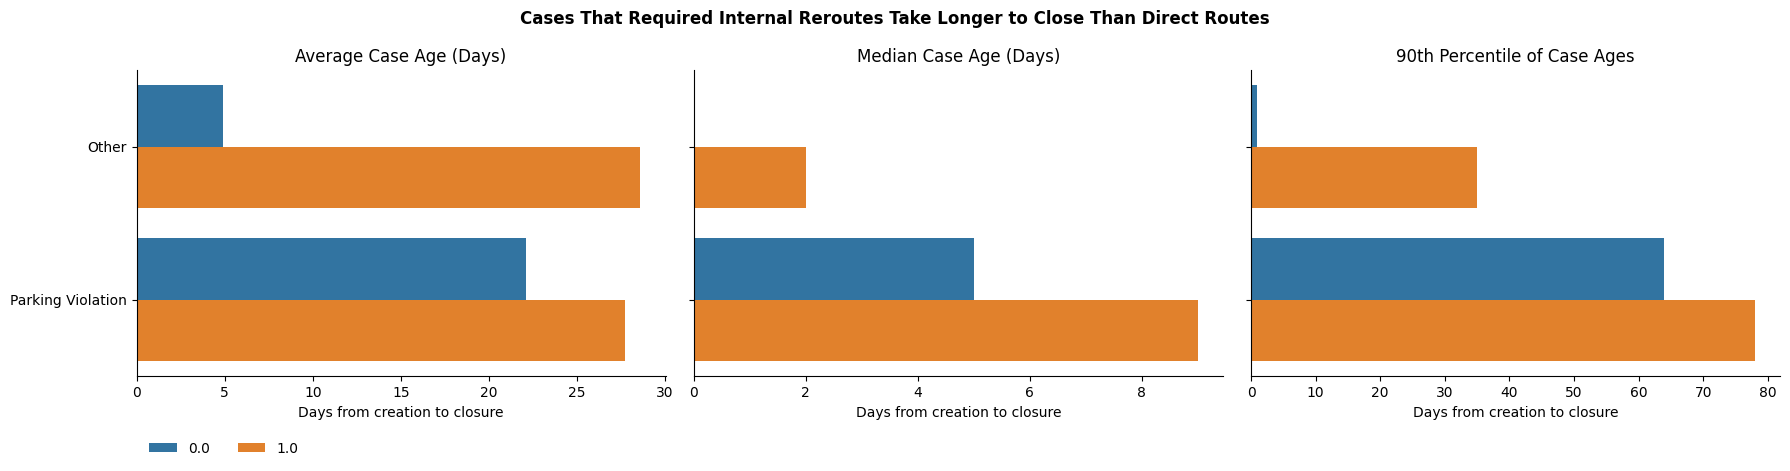

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
fig.suptitle('Cases That Required Internal Reroutes Take Longer to Close Than Direct Routes', fontweight='bold')

sns.barplot(data=plot_info, y='service_name', x='mean', hue='internal_case_referral_flag', ax=axes[0])
axes[0].set_title('Average Case Age (Days)')
axes[0].set_xlabel('Days from creation to closure')
axes[0].set_ylabel('')

sns.barplot(data=plot_info, y='service_name', x='median', hue='internal_case_referral_flag', ax=axes[1])
axes[1].set_title('Median Case Age (Days)')
axes[1].set_xlabel('Days from creation to closure')
axes[1].set_ylabel('')

sns.barplot(data=plot_info, y='service_name', x='top_percentile', hue='internal_case_referral_flag', ax=axes[2])
axes[2].set_title('90th Percentile of Case Ages')
axes[2].set_xlabel('Days from creation to closure')
axes[2].set_ylabel('')

# Clean up redundant legends (keep only one on the first plot)
axes[1].get_legend().remove()
axes[2].get_legend().remove()
axes[0].legend(title='', loc='lower left', bbox_to_anchor=(0, -0.3), ncol=2, frameon=False)

# Remove top and right borders (spines) for a cleaner look
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### *What impacts do back-to-back internal handoffs have operationally\*? Do multiple internally routings affect outcomes?

In [25]:
# Mapper dictionary to simplify `case_reason` to `case_outcome` (5 values)

CODEBOOK = {
    "Misrouted indicator": [
        "Send back to intake", "Not a Storm Water Issue", "Not a Storm Water Violation",
        "Complaint Forwarded", "Refer Elsewhere", "Other Department", 
    ],
    "Duplicate": [
        "Duplicate Report", "Duplicate", "ESD Collections - Duplicate reports", 
        "Closed-Duplicate Case", "Close Dups", "Closed-Duplicate"
    ],
    "Gone on arrival / vanished": [
        "GOA", "Gone on Arrival", "Moved", "ESD Collections - Unable to locate", 
        "Unable to locate", "Unable to Locate - SWC", "Moved / Tidied", 
        "Flooding Subsided", "City Contractor Unable to Locate"
    ],
    "Dismissed / non-actionable": [
        "Could not Complete", "Cleared; No Trash", "Do Not Enforce", "No Violation", 
        "Private/Commercial property", "Closed – Insufficient Info", "No Violation Found", 
        "Legally Parked", "Closed-Not Accepted-Budget", "Evaluated; No action warranted",
        "No Discharge", "Non-Stormwater/Private", "City Contractor No Action Taken", 
        "Closed-Administrative Closure", "ESD Collections - Do Not Service", 
        "Insufficient Case Details", "Closed-No violation", "No issue found", "Profanity",
        "No Email", "ESD Collections - Wrong Week", "Delayed Operator Response",
        "Closed Customer", "Private Property", "ESD Collections - Timely Reporting",
        "STRO-More Info Not Provided", "STRO-No Enforcement", "Allowable Discharge",
        "Event In Compliance", "Channel – No Maintenance", "Closed-Void", "Feedback",
        "STRO-Outside City Jurisdiction", "PD Delay", "Known Outreach Area", 
        "Clean Up Denied", "Closed-Due to Budget", "Encampment on Private Property",
        "Request no longer needed", "Cleared Administratively", "Feedback Received",
        "Graffiti - Private", "Unable to contact requestor", "Service Not Provided"
    ],
    "Action taken": [
        "Externally Referred", "Outside City", "Closed-Referral",
        "PD issue not handled in Get It Done", "Problem resolved", "Compliance Achieved", 
        "Container Emptied", "Impounded", "Cleared and Cleaned", "Cited", 
        "Enforcement Action Taken", "Warned", "Issue Resolved", "City Contractor Resolved", 
        "Closed-Involuntary Compliance", "Problem Abated", "Repaired by City", 
        "Container Removed", "Contact Made", "Request for Resurfacing", "PUD SN Created",
        "Cleared - ESD Cleanup Pending", "Customer Contacted", "Service Provider",
        "Resolved", "Assigned to User", "Closed-Voluntary Compliance",
        "Pending coordination", "Case Open in Accela", "Projects queue", "Revisit",
        "Crew Job Submitted", "Community Relations Officer", "Complete", "Planned Work",
        "Problem Fixed", "STRO-Noise Complaint (People)", "Investigation (Non-Stormw Asset)",
        "Temporary repair", "Provided requested information", "Marked for 72 Hour",
        "Channel – Minor", "Closed-Alternative Compliance", 
        "STRO-Host or Guest Conflict (NCRC)", "Enforcement Feedback", 
        "Active Investigation", "Clean Up Completed", "Sweeping request (Non-Emergency)",
        "Completed", "Blockage Removed", "Closed-Nuisance Referral", "Closed-Referred",
        "Litter", "Encampment on City Property or ROW", "ESD Cleanup", "TED Request Needed"
    ]
}

In [26]:
outcome_palette = {
    'Action taken': '#006989',
    'Gone on arrival / vanished': '#C45700',
    'Duplicate': '#F18F01',
    'Misrouted indicator': '#FFB85C',
    'Dismissed / non-actionable': '#FFEED6'
}

reason_map = {reason: keys for keys, vals in CODEBOOK.items() for reason in vals}

df['case_outcome'] = df['case_reason'].map(reason_map)

In [27]:
reason_map = {reason: keys for keys, vals in CODEBOOK.items() for reason in vals}

df['case_outcome'] = df['case_reason'].map(reason_map)

> Are internal referrals tied to specific service categories?

In [28]:
service_counts = df['service_name'].value_counts()
contingency_table = pd.crosstab(df.loc[df['service_name'].isin(service_counts[service_counts >= 30].index), 'service_name'], df.loc[df['service_name'].isin(service_counts[service_counts >= 30].index), 'internal_case_referral_flag'])
chi2_stat, p_val, dof, expected = stats.chi2_contingency(contingency_table)
print(f'Test statistic: {chi2_stat:.3f}, p-value: {p_val:.3e}, DOF: {dof}')

Test statistic: 259408.349, p-value: 0.000e+00, DOF: 38


We reject the null: specific categories are likely to be flagged for internal referrals.

> Does the number of internal referrals affect the case outcome?

In [29]:
contingency_table = pd.crosstab(df['internal_referral_count'], df['case_outcome'])
chi2_stat, p_val, dof, expected = stats.chi2_contingency(contingency_table)
print(f'Test statistic: {chi2_stat:.3f}, p-value: {p_val:.3e}, DOF: {dof}')

Test statistic: 22826.622, p-value: 0.000e+00, DOF: 52


This result implies that the number of internal referrals are associated with case outcomes.

<!-- If internal referrals are also related response/service delays, then this delay (in ages) means the case outcome, upon arrival, may change within this timeframe. -->

# `internal_referral_count` Analysis

In [30]:
import statsmodels.formula.api as smf
from scipy import stats

In [31]:
mod = smf.ols(formula='case_age_days ~ C(internal_referral_count)', data=df).fit()
print(mod.summary())

                            OLS Regression Results                            
Dep. Variable:          case_age_days   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.014
Method:                 Least Squares   F-statistic:                     1643.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        08:37:41   Log-Likelihood:            -8.8450e+06
No. Observations:             1509417   AIC:                         1.769e+07
Df Residuals:                 1509403   BIC:                         1.769e+07
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Inte

From the open portal (https://data.sandiego.gov/help/articles/tips-getitdone-311-requests/): `case_record_type` in the data contains values that indicate the City group responsible for a problem. These don’t always map with a city department 1:1, but they offer an idea of which department might be responsible.

In [32]:
mod = smf.ols(formula='case_age_days ~ internal_referral_count', data=df).fit()
print(mod.summary())

                            OLS Regression Results                            
Dep. Variable:          case_age_days   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.013
Method:                 Least Squares   F-statistic:                 2.004e+04
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        08:37:41   Log-Likelihood:            -8.8456e+06
No. Observations:             1509417   AIC:                         1.769e+07
Df Residuals:                 1509415   BIC:                         1.769e+07
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

In [33]:
model = smf.ols(formula='case_age_days ~ internal_referral_count * C(case_record_type)', data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          case_age_days   R-squared:                       0.110
Model:                            OLS   Adj. R-squared:                  0.110
Method:                 Least Squares   F-statistic:                     8118.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        08:37:53   Log-Likelihood:            -8.7676e+06
No. Observations:             1509417   AIC:                         1.754e+07
Df Residuals:                 1509393   BIC:                         1.754e+07
Df Model:                          23                                         
Covariance Type:            nonrobust                                         
                                                                                  coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

In [34]:
buckets = [count.values for _, count in df.groupby('internal_referral_count')['case_age_days']]
hstat, pval = stats.kruskal(*buckets)
print('Kruskal-Wallis Test for Case Age by Referral Count')
print(f'statistic: {hstat:.3f}, p-value: {pval:.4e}')

Kruskal-Wallis Test for Case Age by Referral Count
statistic: 47650.739, p-value: 0.0000e+00


- The Kruskal-Wallis test proves that case resolution time is associated with the number of internal referrals,
- the OLS models show that any case with no internal referrals take an average 22 days to be resolved, which increases as more internal referrals occur (plus 60 days for cases with 3 or more internal referrals),
    - 3 or more looks reasonable?
- `Neighborhood Policing`, `Parking`, `ESD Complaint` departments significantly quicker than the average resolution time.

**Net Delays by Department:**

- Traffic Engineering = 21.7 days for every addtional referral,
- TSW = 24.0 days,
- ESD Abatement = 18.8 days,
- Storm Water Code Enforcement = 16.7 days,
- ESD Complaint/Report = 14.7 days,
- Parks and Rec. = 12.0 days,
- Neighborhood Policing = 10.73 days,
- Parking = 3.0 days

In [35]:
mod = smf.ols(formula='case_age_days ~ internal_referral_count + C(service_name)', data=df).fit()
print(mod.summary())

                            OLS Regression Results                            
Dep. Variable:          case_age_days   R-squared:                       0.226
Model:                            OLS   Adj. R-squared:                  0.226
Method:                 Least Squares   F-statistic:                     9986.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        08:38:10   Log-Likelihood:            -8.6461e+06
No. Observations:             1506320   AIC:                         1.729e+07
Df Residuals:                 1506275   BIC:                         1.729e+07
Df Model:                          44                                         
Covariance Type:            nonrobust                                         
                                                                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------

- For any case, one internal referral adds on average 15.9 days to resolution time,
- Here, services `Street Light Maintenance`, `Traffic Sign Maintenance`, and `Vegetation Encroachment` have the most statistical significance. The first two have a backlog.

In [36]:
service_avg_count = df.groupby('service_name')['internal_referral_count'].mean().reset_index()
service_avg_count.sort_values('internal_referral_count', ascending=False, inplace=True)
service_avg_count = service_avg_count.head(15)

/var/folders/sp/1qg6hw2572g23yxdgsh3gbkm0000gn/T/ipykernel_2127/47461082.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='internal_referral_count', y='service_name', data=service_avg_count, palette='crest_r')


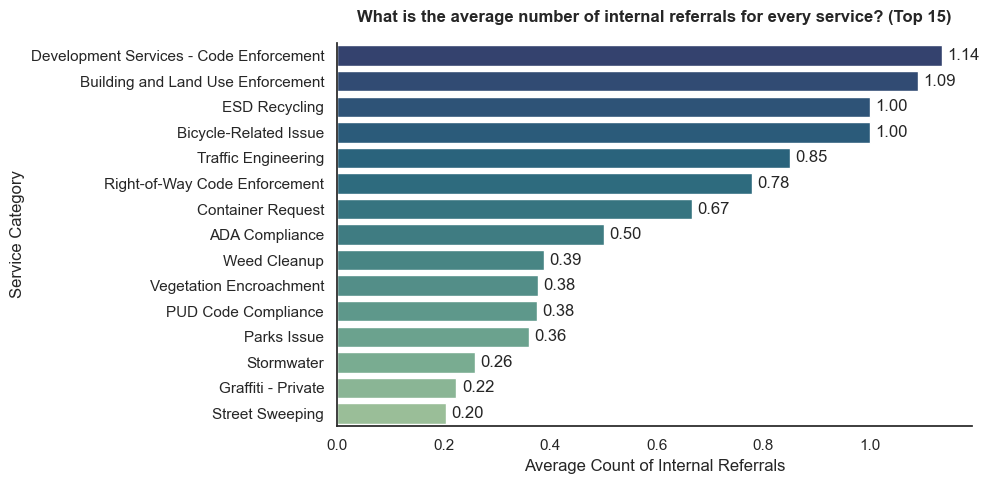

In [37]:
plt.figure(figsize=(10, 5))
sns.set_theme(style='white')

ax = sns.barplot(x='internal_referral_count', y='service_name', data=service_avg_count, palette='crest_r')

plt.title('What is the average number of internal referrals for every service? (Top 15)', fontweight='bold', pad=15)
plt.xlabel('Average Count of Internal Referrals')
plt.ylabel('Service Category')

for p in ax.patches:
    plt.text(p.get_width() + 0.01, p.get_y() + p.get_height()/2, 
             f'{p.get_width():.2f}', va='center')

sns.despine()
plt.tight_layout()
plt.show()

In [38]:
plot_data2 = df[df['internal_case_referral_flag'] == 1.]
avg_count = plot_data2.groupby('service_name')['internal_referral_count'].mean().reset_index()
avg_count.sort_values('internal_referral_count', ascending=False, inplace=True)
avg_count = avg_count.head(15)

In [39]:
department_avg_count = plot_data2.groupby('case_record_type')['internal_referral_count'].mean().reset_index()
department_avg_count.sort_values('internal_referral_count', ascending=False, inplace=True)
department_avg_count = department_avg_count.head(15)

/var/folders/sp/1qg6hw2572g23yxdgsh3gbkm0000gn/T/ipykernel_2127/3410879735.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='internal_referral_count', y='case_record_type', data=department_avg_count, palette='crest_r')


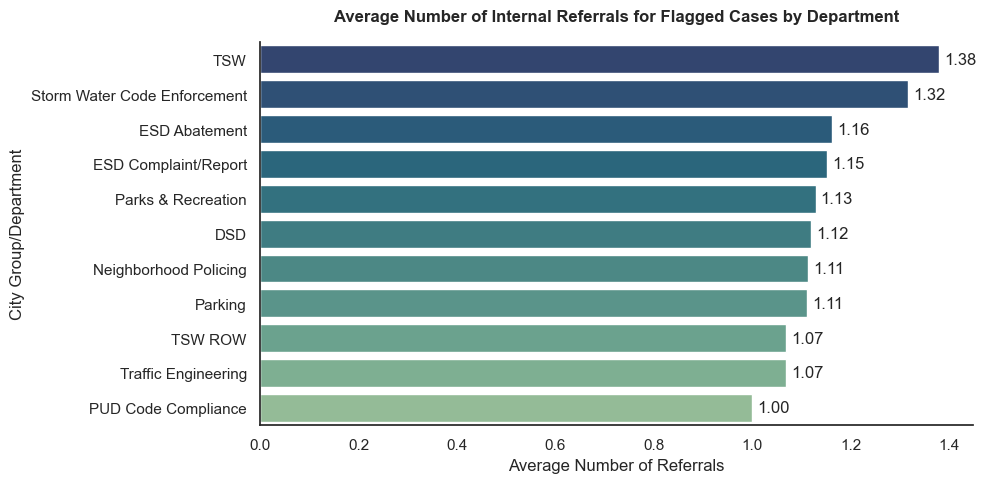

In [40]:
plt.figure(figsize=(10, 5))
sns.set_theme(style='white')

ax = sns.barplot(x='internal_referral_count', y='case_record_type', data=department_avg_count, palette='crest_r')

plt.title('Average Number of Internal Referrals for Flagged Cases by Department', fontweight='bold', pad=15)
plt.xlabel('Average Number of Referrals')
plt.ylabel('City Group/Department')

for p in ax.patches:
    plt.text(p.get_width() + 0.01, p.get_y() + p.get_height()/2, 
             f'{p.get_width():.2f}', va='center')

sns.despine()
plt.tight_layout()
plt.show()

In [41]:
outcome_palette = {
    'Action taken': '#006989',
    'Gone on arrival / vanished': '#C45700',
    'Duplicate': '#F18F01',
    'Misrouted indicator': '#FFB85C',
    'Dismissed / non-actionable': '#FFEED6'
}

reason_map = {reason: keys for keys, vals in CODEBOOK.items() for reason in vals}
df['case_outcome'] = df['case_reason'].map(reason_map)

In [42]:
data2 = df[(df['internal_case_referral_flag'] == 1.) & (df['internal_referral_count'].notna()) & (df['internal_referral_count'] > 0)]

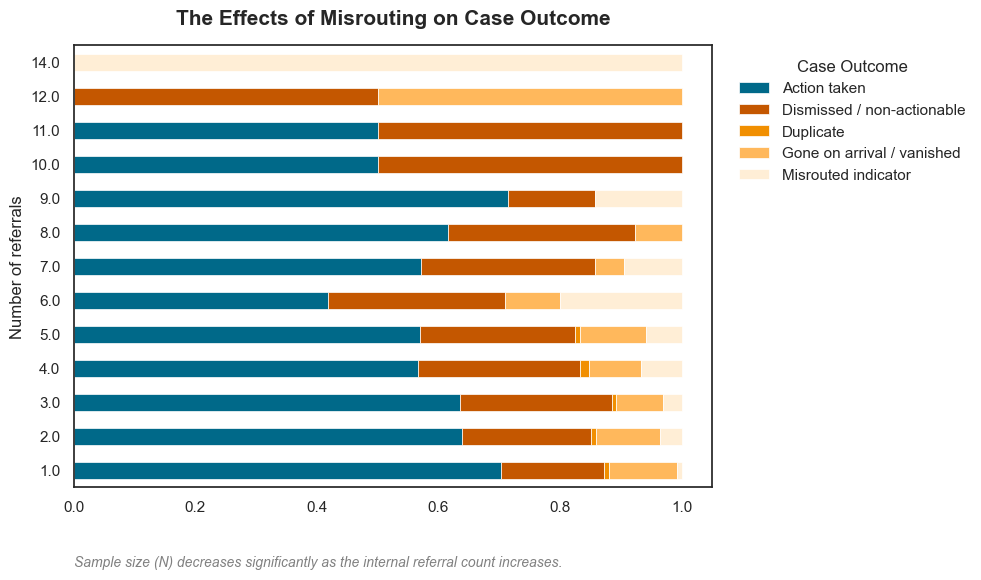

In [43]:
plot_data3 = data2.groupby('internal_referral_count')['case_outcome'].value_counts(normalize=True).unstack()
fig, ax = plt.subplots(figsize=(10, 6))
plot_data3.plot(kind='barh', stacked=True, ax=ax, linewidth=0.5, color=[outcome_palette[c] for c in outcome_palette])
ax.text(0, -0.18, 'Sample size (N) decreases significantly as the internal referral count increases.', transform=ax.transAxes, fontsize=10, style='italic', color='gray')
ax.set_title('The Effects of Misrouting on Case Outcome', pad=15, fontweight='bold', fontsize=15)
ax.set_ylabel('Number of referrals')
plt.legend(title='Case Outcome', bbox_to_anchor=(1.02, 1), frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

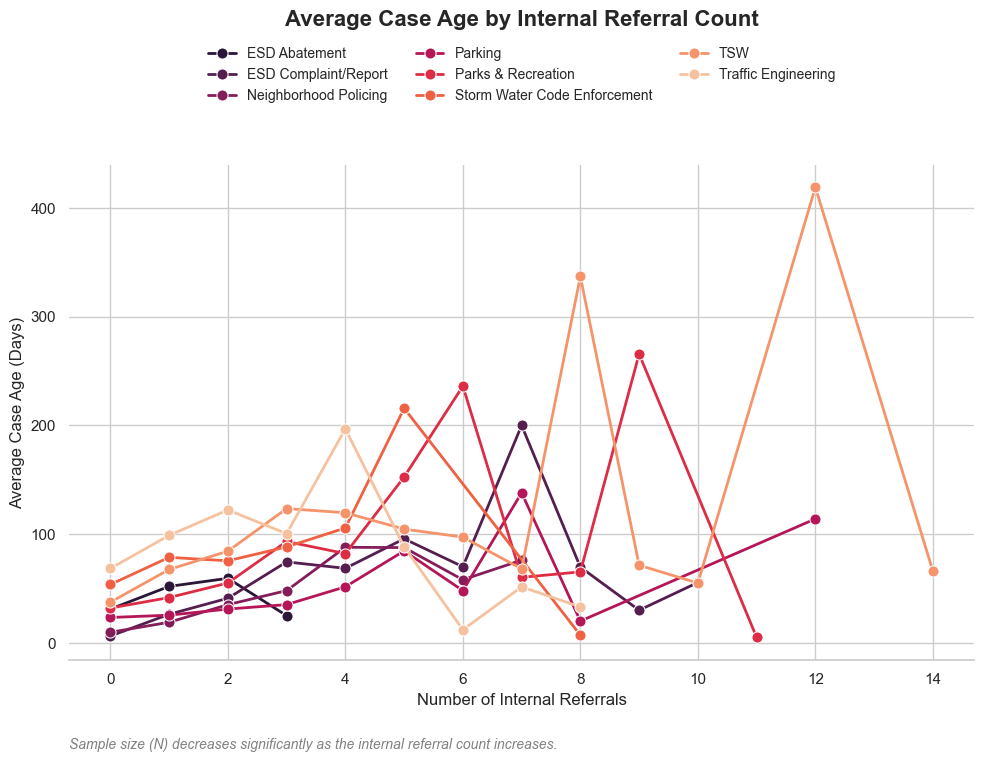

In [44]:
plot_data6 = df.copy()

line_data = plot_data6.groupby(['case_record_type', 'internal_referral_count'])['case_age_days'].mean().reset_index()
our_regression_depts = [
    'Traffic Engineering', 
    'TSW', 
    'ESD Abatement', 
    'Storm Water Code Enforcement', 
    'ESD Complaint/Report', 
    'Parks & Recreation', 
    'Neighborhood Policing', 
    'Parking'
]
line_data = line_data[line_data['case_record_type'].isin(our_regression_depts)]

plt.figure(figsize=(10, 8))
sns.set_theme(style='whitegrid') 

ax = sns.lineplot(data=line_data, x='internal_referral_count', y='case_age_days', hue='case_record_type', marker='o', markersize=8, linewidth=2, palette='rocket')

plt.title('Average Case Age by Internal Referral Count', fontsize=16, fontweight='bold', pad=100, loc='center')
plt.xlabel('Number of Internal Referrals', fontsize=12) 
plt.ylabel('Average Case Age (Days)', fontsize=12) 

plt.legend(
    title='',
    bbox_to_anchor=(0.5, 1.10),
    loc='lower center',
    ncol=3,                     
    frameon=False,              
    fontsize=10
)

ax.text(0, -0.18, 'Sample size (N) decreases significantly as the internal referral count increases.', transform=ax.transAxes, fontsize=10, style='italic', color='gray')

sns.despine(left=True, bottom=False, right=True, top=True)
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

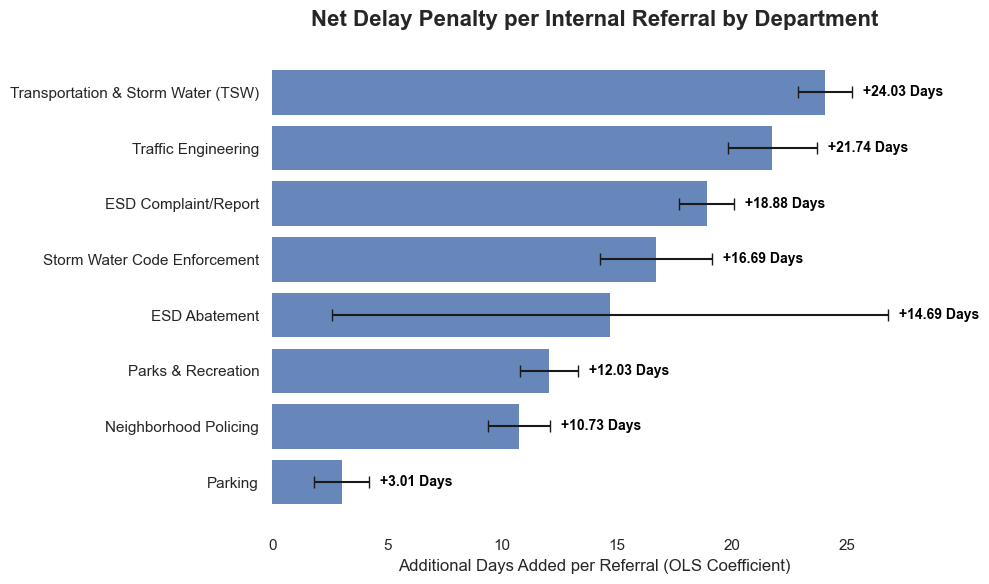

In [45]:
coef_data = pd.DataFrame({
    'department': [
        'Traffic Engineering', 
        'Transportation & Storm Water (TSW)', 
        'ESD Abatement', 
        'Storm Water Code Enforcement', 
        'ESD Complaint/Report', 
        'Parks & Recreation', 
        'Neighborhood Policing', 
        'Parking'
    ],
    # Calculated as: interaction coefficient + baseline internal_referral_count (-31.79)
    'net_delay_days': [
        21.74,   # 53.53 - 31.79
        24.03,   # 55.82 - 31.79
        14.69,   # 46.48 - 31.79
        16.69,   # 48.48 - 31.79
        18.88,   # 50.67 - 31.79
        12.03,   # 43.82 - 31.79
        10.73,   # 42.52 - 31.79
        3.01     # 34.80 - 31.79
    ],
    # Pulled directly from the "std err" column of your cleaned OLS output
    'error_margin': [
        1.93,    # Traffic Engineering
        1.18,    # TSW
        12.10,   # ESD Abatement
        2.44,    # Storm Water Code Enforcement
        1.19,    # ESD Complaint/Report
        1.25,    # Parks & Recreation
        1.34,    # Neighborhood Policing
        1.19     # Parking
    ] 
})
coef_data = coef_data.sort_values(by='net_delay_days', ascending=True)

plt.figure(figsize=(10, 6))
sns.set_theme(style='white')
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    y=coef_data['department'], 
    width=coef_data['net_delay_days'], 
    xerr=coef_data['error_margin'], 
    edgecolor='none',
    alpha=0.85,
    capsize=4
)

plt.title('Net Delay Penalty per Internal Referral by Department', fontsize=16, fontweight='bold', pad=16)
plt.xlabel('Additional Days Added per Referral (OLS Coefficient)', fontsize=12)
plt.ylabel('', fontsize=12)

ax.bar_label(
    bars, 
    fmt=' +%.2f Days', 
    padding=5,
    fontsize=10, 
    fontweight='bold',
    color='black'
)

plt.xlim(0, 28)
sns.despine(left=True, bottom=True, right=True, top=True)
plt.tight_layout()
plt.show()

In [46]:
df['internal_referral_count_discrete'] = df['internal_referral_count'].astype('category')

In [47]:
df.groupby('case_record_type')['internal_referral_count_discrete'].describe()

,count,unique,top,freq
case_record_type,,,,
DSD,14128.0,8.0,1.0,8887.0
ESD Abatement,398.0,4.0,0.0,367.0
ESD Complaint/Report,534288.0,11.0,0.0,517556.0
ESD Event/Service,1.0,1.0,0.0,1.0
Neighborhood Policing,181289.0,8.0,0.0,173628.0
PUD Code Compliance,8.0,2.0,0.0,5.0
Parking,271849.0,10.0,0.0,252806.0
Parks & Recreation,42641.0,11.0,0.0,27255.0
Special Situation,1.0,1.0,0.0,1.0


In [48]:
df.groupby('service_name')['internal_referral_count_discrete'].describe()

,count,unique,top,freq
service_name,,,,
ADA Compliance,2.0,2.0,0.0,1.0
Bicycle-Related Issue,9.0,3.0,1.0,5.0
Biohazard,483.0,1.0,0.0,483.0
Building and Land Use Enforcement,2043.0,6.0,1.0,1861.0
Container Request,3.0,2.0,1.0,2.0
Dead Animal,16612.0,4.0,0.0,16441.0
Development Services - Code Enforcement,3599.0,8.0,1.0,3127.0
ESD Collections,7795.0,2.0,0.0,7709.0
ESD Recycling,1.0,1.0,1.0,1.0


In [49]:
df.loc[df['service_name'] == 'Encampment', 'case_outcome'].value_counts()

case_outcome
Action taken                  100697
Gone on arrival / vanished     79344
Dismissed / non-actionable     15750
Misrouted indicator              792
Duplicate                        270
Name: count, dtype: int64

In [50]:
df.loc[(df['service_name'] == 'Encampment') & (df['case_outcome'] == 'Action taken'), ['public_description', 'case_record_type', 'service_name', 'status', 'referred', 'case_reason', 'owner_type', 'modified_by_worker', 'internal_case_referral_flag', 'internal_referral_count']]

,public_description,case_record_type,service_name,status,referred,case_reason,owner_type,modified_by_worker,internal_case_referral_flag,internal_referral_count
52,Homeless encampment in dangerous location righ...,Neighborhood Policing,Encampment,Referred,appropriate department or agency,Externally Referred,queue,True,0.0,0.0
73,Encampment is growing - please remove asap. It...,ESD Complaint/Report,Encampment,Closed,NaN,Problem resolved,queue,True,0.0,0.0
98,Homeless,Neighborhood Policing,Encampment,Closed,NaN,Cleared and Cleaned,queue,True,0.0,0.0
120,"Been parked their for weeks, trash outside, un...",Neighborhood Policing,Encampment,Closed,NaN,Contact Made,queue,True,0.0,0.0
130,Drugs being used in bike lane.,Neighborhood Policing,Encampment,Closed,NaN,Contact Made,queue,True,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
1509384,Homeless encampment in front of residence. Ver...,Neighborhood Policing,Encampment,Closed,NaN,Cleared and Cleaned,worker,True,1.0,1.0
1509385,Homeless individual âlighting upâ in front...,Neighborhood Policing,Encampment,Referred,port of sd,Externally Referred,queue,True,0.0,0.0
1509388,10 people for several evenings are seen gather...,Neighborhood Policing,Encampment,Referred,caltrans,Externally Referred,queue,True,0.0,0.0
1509395,Homeless encampment,ESD Complaint/Report,Encampment,Closed,NaN,Problem resolved,queue,True,0.0,0.0


There *are* two referrals (police and ESD), but they are not flagged.

In [51]:
df.loc[(df['service_name'] == 'Encampment') & (df['case_record_type'].isin(['ESD Complaint/Report', 'ESD Abatement','Parks & Recreation', 'TSW', 'DSD', 'TSW ROW'])), ['public_description', 'case_record_type', 'service_name', 'status', 'referred', 'case_reason', 'owner_type', 'modified_by_worker', 'internal_case_referral_flag', 'internal_referral_count']]

,public_description,case_record_type,service_name,status,referred,case_reason,owner_type,modified_by_worker,internal_case_referral_flag,internal_referral_count
73,Encampment is growing - please remove asap. It...,ESD Complaint/Report,Encampment,Closed,NaN,Problem resolved,queue,True,0.0,0.0
137,Encampment,ESD Complaint/Report,Encampment,Closed,NaN,Problem resolved,queue,True,0.0,0.0
153,Huge homeless encampment,ESD Abatement,Encampment,Closed,NaN,Problem resolved,queue,True,0.0,0.0
224,Encampment,ESD Complaint/Report,Encampment,Closed,NaN,Cleared - ESD Cleanup Pending,queue,True,0.0,0.0
254,Abandoned tent with property inside,ESD Complaint/Report,Encampment,Closed,NaN,Problem resolved,queue,True,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
1509254,Multiple homeless encampments under the bridge,ESD Complaint/Report,Encampment,Closed,NaN,Problem resolved,queue,True,0.0,0.0
1509261,This area used to be a beautiful place to walk...,ESD Complaint/Report,Encampment,Closed,NaN,No Violation,queue,True,1.0,1.0
1509304,open air bike stealing amd chop shop operation,ESD Complaint/Report,Encampment,Closed,NaN,No Violation,queue,True,0.0,0.0
1509345,Encampment set up on end of 20th street next t...,ESD Complaint/Report,Encampment,Closed,NaN,Custom,queue,True,0.0,0.0
